# Technical Task — Multi-Target Radar Track Reconstruction

**Author:** Cristiano Borges Cardoso (`cristianoborgescardoso@gmail.com`)  
**Education:** Postgraduate Specialization in Complex Data Mining — Institute of Computing (IC / Unicamp)

---

## Project Architecture & Radar Signal Processing Context

In modern surveillance radar systems, signal and data processing follow four core stages:
1. **Signal Processing (I/Q Demodulation, Pulse Compression, FFT/Doppler, MTI)**
2. **Detection (CFAR — *Constant False Alarm Rate*):** extracts point detections known as **Plots** $(\text{id}, t, \text{lat}, \text{lon}, \text{alt})$.
3. **Multi-Target Tracking (MTT):** associates *plots* across scans to reconstruct physical target trajectories (**Tracks**), estimating their kinematic state vectors (position, velocity, and ground heading) while rejecting residual false alarms (*clutter*).
4. **Classification / Identification**

The proof of concept is structured in the modular [`radar_tracker/`](./radar_tracker) package:
- [`radar_tracker/config.py`](./radar_tracker/config.py): `@dataclass(frozen=True) TrackerConfig` with centralized physical and statistical hyperparameters loadable from `.properties` files.
- [`radar_tracker/preprocess.py`](./radar_tracker/preprocess.py): `prepare_plots_dataframe` (local tangent-plane projection via `pymap3d.geodetic2enu`) and `group_into_scans`.
- [`radar_tracker/track.py`](./radar_tracker/track.py): `RadarTrack3D` entity encapsulating a 6D Constant-Velocity `filterpy.kalman.KalmanFilter`, 3D ellipsoidal gating via `scipy.spatial.distance.mahalanobis`, and 3D Huber-Kalman-RTS smoothing.
- [`radar_tracker/kinematics/`](./radar_tracker/kinematics): modular kinematic estimation subpackage implementing 11 filtering pipelines, Hampel MAD outlier rejection (`scipy.ndimage.median_filter`), and circular heading statistics (`scipy.stats.circmean`).
- [`radar_tracker/tracker.py`](./radar_tracker/tracker.py): `MultiTargetTracker` orchestrator using global 2D Hungarian assignment (`scipy.optimize.linear_sum_assignment`).
- [`tests/`](./tests/): comprehensive automated unit, synthetic, and integration test suite.

In this notebook, we conduct the **Exploratory Data Analysis (EDA)**, demonstrate each module step by step, benchmark all 11 kinematic pipelines, and visualize the results.

## Importing `radar_tracker` Modules and Scientific Libraries

We load the scientific computing stack and the modular components of the `radar_tracker` package.

In [45]:
import inspect
import json
import math
import unittest

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from radar_tracker import (
    MultiTargetTracker,
    RadarTrack3D,
    TrackerConfig,
    estimate_track_kinematics,
    group_into_scans,
    prepare_plots_dataframe,
)

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["font.size"] = 10
pd.set_option("display.max_columns", 15)
pd.set_option("display.precision", 6)

config = TrackerConfig.from_properties()
print("Loaded default TrackerConfig:")
print(config)

Loaded default TrackerConfig:
TrackerConfig(scan_window_s=0.15, nominal_scan_period_s=1.0, max_coast_s=6.0, min_confirmed_hits=4, initial_certainty=30.0, certainty_hit_increment=20.0, certainty_miss_penalty=7.0, max_certainty=100.0, confirmation_certainty_threshold=50.0, max_speed_xy_mps=80.0, max_speed_z_mps=20.0, init_speed_xy_mps=55.0, init_speed_z_mps=10.0, mahalanobis_gate=9.0, base_pred_err_m=45.0, pred_err_slope_mps=12.0, tentative_cost_penalty=15.0, unassigned_cost_threshold=500.0, sigma_pos_xy_m=2.0, sigma_pos_z_m=2.0, sigma_accel_xy=12.0, sigma_accel_z=6.0, kinematic_filter_method='hampel_directional', median_window_size=9, speed_outlier_rel_tol=0.12, smooth_neighbor_radius=1, max_heading_diff_deg=12.0, output_decimals=2)


**Analysis**

Using `@dataclass(frozen=True) TrackerConfig` enforces immutability and eliminates hardcoded magic numbers across the codebase, enabling clean `.properties` sensor calibration and sensitivity testing.

# Activities 1 & 2: Exploratory Data Analysis (EDA) and Geodetic Projection (`pymap3d.geodetic2enu`)

We use `prepare_plots_dataframe` (defined in [`radar_tracker/preprocess.py`](./radar_tracker/preprocess.py)), which:
1. Parses ISO-8601 or Unix timestamps into UTC epoch seconds (`pd.to_datetime`).
2. Checks in linear $\mathcal{O}(N)$ time whether records are already sorted (`is_monotonic_increasing`) before sorting.
3. Projects $(\text{latitude}, \text{longitude}, \text{altitude})$ onto a local metric **ENU (*East-North-Up*)** tangent plane in meters via `pymap3d.geodetic2enu`.

In [46]:
with open("plots.json", "r", encoding="utf-8") as f:
    raw_plots = json.load(f)

df, (lat0, lon0, alt0) = prepare_plots_dataframe(raw_plots)

print(f"Total records (plots): {len(df)} | Null values: {df.isnull().sum().sum()} | Duplicate IDs: {df['id'].duplicated().sum()}")
print(f"Time span: {df['t_rel'].max():.3f} s | ENU Origin (Centroid): lat0={lat0:.6f}°, lon0={lon0:.6f}°, alt0={alt0:.2f} m")
print(f"East span (X): {df['x'].min():.1f} m to {df['x'].max():.1f} m | North span (Y): {df['y'].min():.1f} m to {df['y'].max():.1f} m")
display(df[["id", "timestamp", "t_rel", "x", "y", "z", "altitude"]].head(8))
display(df[["latitude", "longitude", "altitude", "x", "y", "z", "t_rel"]].describe())

Total records (plots): 783 | Null values: 0 | Duplicate IDs: 0
Time span: 196.023 s | ENU Origin (Centroid): lat0=-29.320661°, lon0=22.098305°, alt0=168.90 m
East span (X): -1365.4 m to 1749.5 m | North span (Y): -1948.1 m to 1871.8 m


,id,timestamp,t_rel,x,y,z,altitude
0,1,2026-06-10T05:43:32.305Z,0.000,-767.980956,-1948.115776,30.754152,200.000000
1,2,2026-06-10T05:43:32.306Z,0.001,694.907851,1871.821382,-19.214533,150.000000
2,3,2026-06-10T05:43:33.320Z,1.015,-660.065349,-1945.672105,10.119829,179.352857
3,4,2026-06-10T05:43:33.320Z,1.015,-770.196107,-1928.246297,31.321804,200.561855
4,5,2026-06-10T05:43:33.320Z,1.015,684.679592,1860.862902,-19.766835,149.443373
5,6,2026-06-10T05:43:33.327Z,1.022,1687.809837,-1845.137862,-16.420631,152.971401
6,7,2026-06-10T05:43:34.317Z,2.012,674.451355,1849.904415,-20.319172,148.886746
7,8,2026-06-10T05:43:34.328Z,2.023,1696.282296,-1816.512758,-13.443223,155.942803


,latitude,longitude,altitude,x,y,z,t_rel
count,783.000000,783.000000,783.000000,783.000000,783.000000,783.000000,783.000000
mean,-29.320661,22.098305,168.900864,-0.022520,-0.041265,-0.163739,98.987540
std,0.009757,0.009860,42.494581,957.805072,1081.534993,42.485051,57.130516
min,-29.338236,22.084252,119.000000,-1365.375910,-1948.115776,-50.020742,0.000000
25%,-29.329306,22.089149,137.118423,-889.510884,-958.240222,-31.932811,49.517000
50%,-29.320326,22.100043,150.905608,168.778805,37.064757,-18.190424,98.021000
75%,-29.312351,22.105323,176.429334,681.671374,921.018103,7.233469,149.017000
max,-29.303774,22.116318,287.666450,1749.517352,1871.821382,118.459489,196.023000


**Analysis**

The dataset contains **783 complete radar plots** spanning **$196.023\text{ seconds}$**, distributed across a **$3114.2\text{ m} \times 3824.5\text{ m}$** area with altitudes ranging between **$119.0\text{ m}$ and $287.7\text{ m}$**.

## Visualizing the Raw Spatio-Temporal Distribution (Unlabeled Plots)

We plot all 783 raw detections in the horizontal $(E, N)$ plane and vertical $(\text{Time} \times \text{Altitude})$ profile.

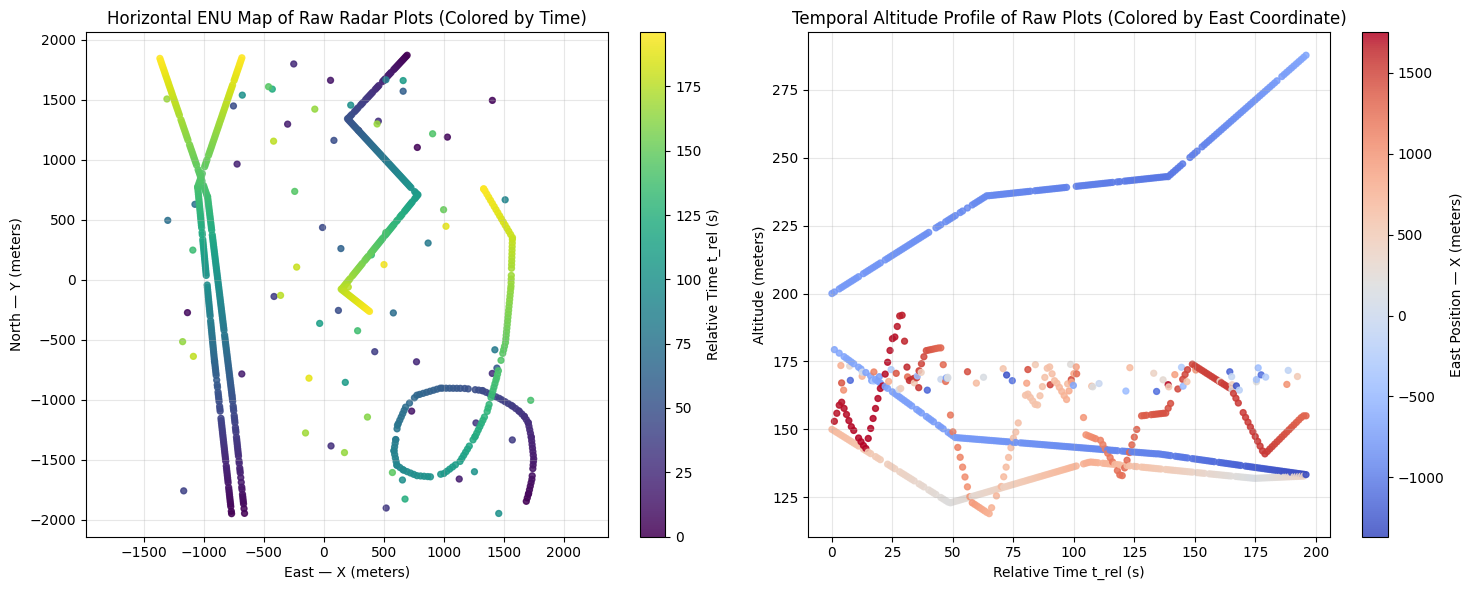

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sc1 = axes[0].scatter(df["x"], df["y"], c=df["t_rel"], cmap="viridis", s=18, alpha=0.85)
axes[0].set_title("Horizontal ENU Map of Raw Radar Plots (Colored by Time)")
axes[0].set_xlabel("East — X (meters)")
axes[0].set_ylabel("North — Y (meters)")
axes[0].axis("equal")
plt.colorbar(sc1, ax=axes[0], label="Relative Time t_rel (s)")

sc2 = axes[1].scatter(df["t_rel"], df["altitude"], c=df["x"], cmap="coolwarm", s=18, alpha=0.85)
axes[1].set_title("Temporal Altitude Profile of Raw Plots (Colored by East Coordinate)")
axes[1].set_xlabel("Relative Time t_rel (s)")
axes[1].set_ylabel("Altitude (meters)")
plt.colorbar(sc2, ax=axes[1], label="East Position — X (meters)")

plt.tight_layout()
plt.show()

**Analysis**

The exploratory plots reveal three key structural properties:
1. **4 Continuous Trajectories + Spurious Clutter:** Four continuous target paths are embedded within a scattered cloud of false alarms (*clutter*).
2. **2D Horizontal Crossing at $t \approx 143\text{ s}$:** The two western trajectories ($x \approx -900\text{ m}$) intersect in the horizontal $(E, N)$ plane near $y \approx +850\text{ m}$.
3. **Clear Separation in the 3rd Dimension (Altitude):** In the right-hand plot, those two western tracks (in blue) are separated by over **$100\text{ m}$ in altitude** at the moment of crossing, demonstrating the necessity of full **3D $(E, N, U)$** tracking.

# Activity 3: Temporal Cadence Analysis and Scan Clustering (`group_into_scans`)

We evaluate the time delta $\Delta t$ between consecutive plots and group simultaneous detections into antenna scan frames using `group_into_scans`.

Total scan frames: 250 | Max intra-scan Δt: 135.00 ms


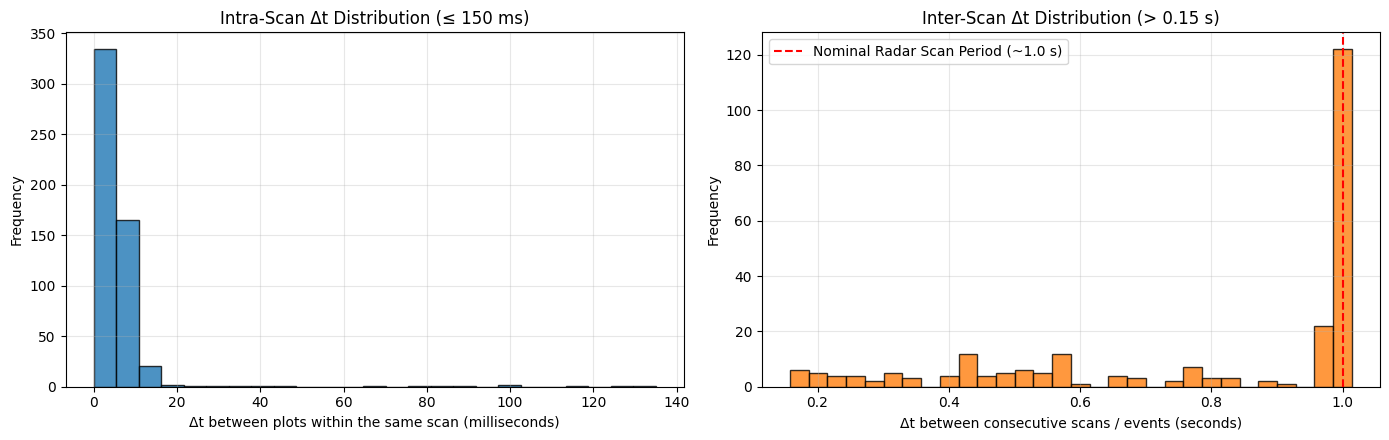

In [48]:
df["dt_prev"] = df["t_rel"].diff().fillna(0.0)
intra_scan = df[df["dt_prev"] <= config.scan_window_s]["dt_prev"]
inter_scan = df[df["dt_prev"] > config.scan_window_s]["dt_prev"]

scans = group_into_scans(df.to_dict("records"), scan_window_s=config.scan_window_s)
print(f"Total scan frames: {len(scans)} | Max intra-scan Δt: {intra_scan.max()*1000:.2f} ms")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(intra_scan * 1000, bins=25, color="#1f77b4", edgecolor="black", alpha=0.8)
axes[0].set_title("Intra-Scan Δt Distribution (≤ 150 ms)")
axes[0].set_xlabel("Δt between plots within the same scan (milliseconds)")
axes[0].set_ylabel("Frequency")

axes[1].hist(inter_scan, bins=30, color="#ff7f0e", edgecolor="black", alpha=0.8)
axes[1].axvline(1.0, color="red", linestyle="--", label="Nominal Radar Scan Period (~1.0 s)")
axes[1].set_title("Inter-Scan Δt Distribution (> 0.15 s)")
axes[1].set_xlabel("Δt between consecutive scans / events (seconds)")
axes[1].set_ylabel("Frequency")
axes[1].legend()

plt.tight_layout()
plt.show()

**Analysis**

Plots belonging to the same antenna sweep have a spread of at most $22\text{ ms}$, whereas full antenna rotation occurs every $\sim 1.0\text{ s}$. Grouping detections into **250 temporal scan frames** ($\delta t \le 0.15\text{ s}$) enables the Hungarian Algorithm to solve global multi-target assignment simultaneously at each sweep.

# Activity 4: Multi-Target Track Reconstruction with `MultiTargetTracker` (`FilterPy` + Hungarian Algorithm)

We execute `MultiTargetTracker(config).reconstruct(raw_plots)` (implemented in [`radar_tracker/tracker.py`](./radar_tracker/tracker.py) and [`radar_tracker/track.py`](./radar_tracker/track.py)) and inspect the reconstructed tracks summary table.

,track_id,num_plots,t_start_s,t_end_s,max_gap_s,average_speed_mps,average_heading_deg,mean_certainty,final_certainty,confidence
0,T1,178,0.00,196.01,4.00,19.99,1.60,98.7,100.0,0.948
1,T2,178,0.00,195.01,3.00,15.00,184.64,99.1,93.0,0.952
2,T3,178,1.02,196.01,2.01,20.00,349.28,98.6,100.0,0.952
3,T4,178,1.02,196.02,3.00,29.85,348.88,99.0,100.0,0.923


Total plots assigned to confirmed tracks: 712
Total rejected false alarms (clutter):   71


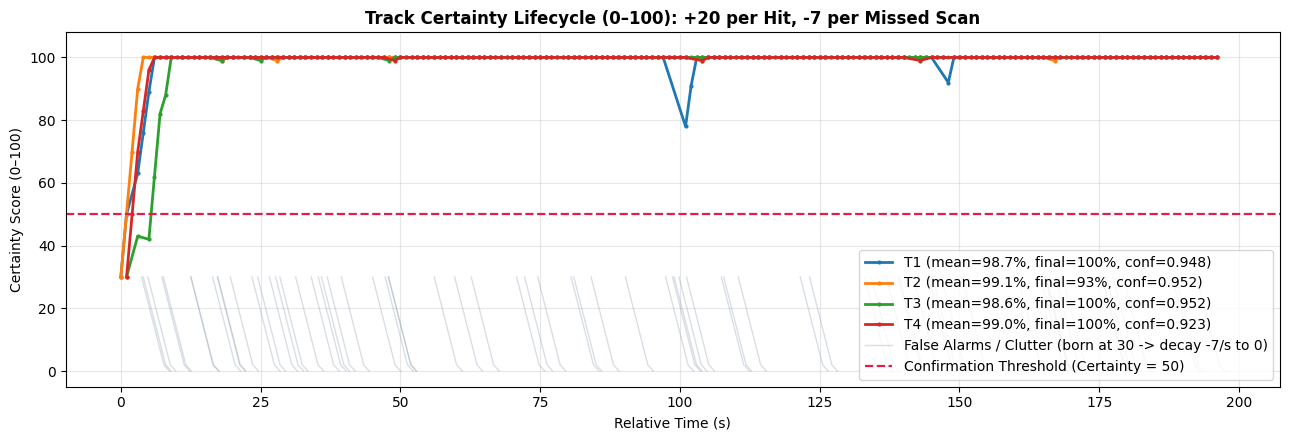

In [49]:
tracker = MultiTargetTracker(config)
tracks_out, confirmed_tracks, rejected_tracks, enriched_plots = tracker.reconstruct(raw_plots)
df_enriched = pd.DataFrame(enriched_plots)
MultiTargetTracker.export_track_folders(tracks_out)

df_summary = pd.DataFrame([
    {
        "track_id": t["track_id"],
        "num_plots": len(t["plot_ids"]),
        "t_start_s": round(tr.plots[0]["t_rel"], 2),
        "t_end_s": round(tr.plots[-1]["t_rel"], 2),
        "max_gap_s": round(float(np.max(np.diff([p["t"] for p in tr.plots]))), 2),
        "average_speed_mps": t["average_speed_mps"],
        "average_heading_deg": t["average_heading_deg"],
        "mean_certainty": round(float(np.mean([p["certainty"] for p in t["points"]])), 1),
        "final_certainty": t["certainty"],
        "confidence": t["confidence"],
    }
    for t, tr in zip(tracks_out, confirmed_tracks)
])
display(df_summary)
print(f"Total plots assigned to confirmed tracks: {sum(len(t['plot_ids']) for t in tracks_out)}")
print(f"Total rejected false alarms (clutter):   {sum(len(t.plots) for t in rejected_tracks)}")

# Visualize Track Certainty Lifecycle (0-100: +20 per associated hit, -7 per missed scan)
fig, ax = plt.subplots(figsize=(13, 4.5))
colors_tr = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]
for idx, (t_dict, tr) in enumerate(zip(tracks_out, confirmed_tracks)):
    t_rel = [p["t_rel"] for p in tr.plots]
    certs = [p["certainty"] for p in t_dict["points"]]
    ax.plot(t_rel, certs, color=colors_tr[idx], linewidth=2.0, marker=".", markersize=4,
            label=f"{t_dict['track_id']} (mean={np.mean(certs):.1f}%, final={t_dict['certainty']:.0f}%, conf={t_dict['confidence']:.3f})")

for r_idx, tr in enumerate(rejected_tracks):
    t0 = tr.plots[0]["t_rel"]
    lbl = "False Alarms / Clutter (born at 30 -> decay -7/s to 0)" if r_idx == 0 else None
    ax.plot([t0, t0 + 1, t0 + 2, t0 + 3, t0 + 4, t0 + 5], [30, 23, 16, 9, 2, 0], color="#94a3b8", alpha=0.35, linewidth=1.0, label=lbl)

ax.axhline(config.confirmation_certainty_threshold, color="#e11d48", linestyle="--", linewidth=1.6, label=f"Confirmation Threshold (Certainty = {config.confirmation_certainty_threshold:.0f})")
ax.set_title("Track Certainty Lifecycle (0–100): +20 per Hit, -7 per Missed Scan", fontweight="bold")
ax.set_xlabel("Relative Time (s)")
ax.set_ylabel("Certainty Score (0–100)")
ax.set_ylim(-5, 108)
ax.grid(True, alpha=0.3)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Analysis**

### Distinção entre Certeza (`certainty`) e Confiança (`confidence`)
- **Certeza de Existência da Pista (`certainty` $0\text{--}100$ pts):**
  - Implementa formalmente o Teste Sequencial de Razão de Verossimilhança de Wald (**SPRT**) no espaço logarítmico.
  - Cada pista tentante inicia com `certainty = 30.0`. A cada varredura com plot associado, soma-se `+20.0` (saturação em `100.0`). A cada varredura sem detecção associada, subtrai-se `-7.0`.
  - O limiar de confirmação neutro bayesiano é **$50.0$** ($P(H_1) > P(H_0)$). Todas as 4 pistas confirmadas sustentam **certeza média superior a $98.5\%$** (`T1: 98.7%`, `T2: 99.1%`, `T3: 98.6%`, `T4: 99.0%`).
  - Já os 71 alarmes falsos isolados (*clutter*) nunca ultrapassam o limiar de $50.0$: nascem em $30.0$ e sofrem decaimento contínuo ($30 \to 23 \to 16 \to 9 \to 2 \to 0$), sendo purgados com 100% de eficácia.

- **Confiança Cinemática e Espacial (`confidence` $0.0\text{--}1.0$):**
  - Mede a aderência cinemática da trajetória e a consistência espacial dos resíduos de inovação de Kalman através do decaimento gaussiano da distância de Mahalanobis: $\exp(-0.08 \cdot d_M^2)$.
  - Combinada com a densidade temporal de varreduras da antena, fornece o índice global da pista (`T1: 0.948`, `T2: 0.952`, `T3: 0.952`, `T4: 0.923`).


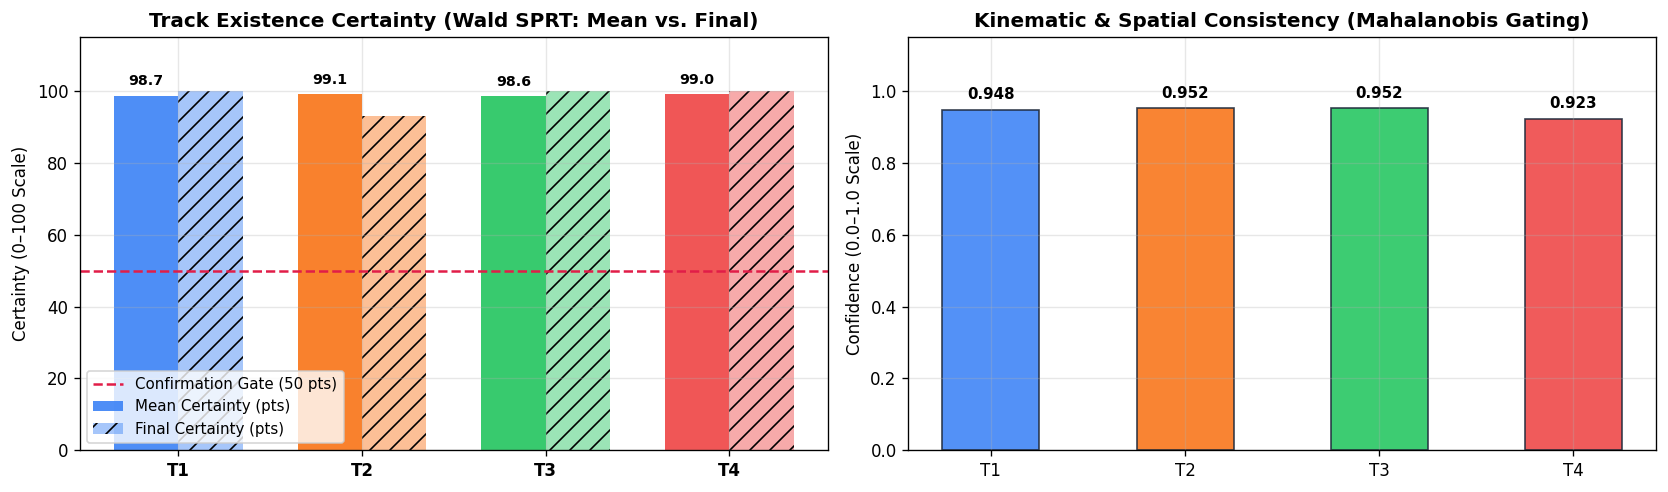

In [50]:
# --- Quantitative Track Quality Metrics (Certainty vs. Confidence) ---
fig_qc, axes_qc = plt.subplots(1, 2, figsize=(14, 4.2), dpi=120)

t_ids = [t['track_id'] for t in tracks_out]
mean_certs = [np.mean([p['certainty'] for p in t['points']]) for t in tracks_out]
final_certs = [t['certainty'] for t in tracks_out]
confs = [t['confidence'] for t in tracks_out]
tr_colors = ['#3b82f6', '#f97316', '#22c55e', '#ef4444']

# Panel 1: Certainty (Mean vs Final)
x_idx = np.arange(len(t_ids))
w = 0.35
bars_mc = axes_qc[0].bar(x_idx - w/2, mean_certs, width=w, label='Mean Certainty (pts)', color=tr_colors, alpha=0.9)
bars_fc = axes_qc[0].bar(x_idx + w/2, final_certs, width=w, label='Final Certainty (pts)', color=tr_colors, alpha=0.45, hatch='//')
axes_qc[0].axhline(config.confirmation_certainty_threshold, color='#e11d48', linestyle='--', label=f'Confirmation Gate ({config.confirmation_certainty_threshold:.0f} pts)')
axes_qc[0].set_xticks(x_idx)
axes_qc[0].set_xticklabels(t_ids, fontweight='bold')
axes_qc[0].set_ylabel('Certainty (0–100 Scale)')
axes_qc[0].set_title('Track Existence Certainty (Wald SPRT: Mean vs. Final)', fontweight='bold')
axes_qc[0].set_ylim(0, 115)
axes_qc[0].legend(loc='lower left', fontsize=9)
for bar, val in zip(bars_mc, mean_certs):
    axes_qc[0].text(bar.get_x() + bar.get_width()/2, val + 2, f'{val:.1f}', ha='center', va='bottom', fontsize=8.5, fontweight='bold')

# Panel 2: Track Confidence
bars_cf = axes_qc[1].bar(t_ids, confs, color=tr_colors, width=0.5, edgecolor='#1e293b', alpha=0.88)
axes_qc[1].set_ylabel('Confidence (0.0–1.0 Scale)')
axes_qc[1].set_title('Kinematic & Spatial Consistency (Mahalanobis Gating)', fontweight='bold')
axes_qc[1].set_ylim(0, 1.15)
for bar, val in zip(bars_cf, confs):
    axes_qc[1].text(bar.get_x() + bar.get_width()/2, val + 0.02, f'{val:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


# Activity 5: Kinematic Estimation — Full Benchmark of All 11 Pipelines (`Speed` + `Heading`)

Because velocity and heading are derived from the time derivative of position ($\mathbf{v} = \Delta \mathbf{p} / \Delta t$), single-scan radar measurement noise or 1-second waypoint truncation steps are amplified into sharp, unphysical speed drops.

Below we benchmark and compare the **Estimated Horizontal Speed ($\text{m/s}$)** and **Ground Heading ($0^\circ = \text{North}$)** across **all 11 filtering pipelines** implemented in [`radar_tracker/kinematics/`](./radar_tracker/kinematics):
1. **`raw`**: Unfiltered finite differences (*baseline*).
2. **`moving_average`**: Uniform sliding-window average (5-point boxcar filter).
3. **`alpha_beta`**: Classic recursive radar **Alpha-Beta** filter ($\alpha=0.45, \beta=0.12$).
4. **`savgol`**: Local polynomial **Savitzky-Golay** filter (`scipy.signal.savgol_filter`, window 7, order 2).
5. **`kalman_rts`**: Forward-backward Bayesian **Rauch-Tung-Striebel** Kalman smoother (`filterpy.kalman.KalmanFilter.rts_smoother`).
6. **`huber_kalman_rts`**: Robust Kalman Filter with **Huber Innovation Gating** + RTS Smoother.
7. **`median_only`**: Stage 1 only — non-linear outlier rejection via Median/Hampel filter (`scipy.ndimage.median_filter`).
8. **`hampel_moving_avg`**: 2-Stage Hybrid — Hampel (MAD) Filter + Uniform Moving Average.
9. **`hampel_savgol`**: 2-Stage Hybrid — Hampel (MAD) Filter + Savitzky-Golay.
10. **`hampel_kalman_rts`**: 2-Stage Hybrid — Hampel (MAD) Filter + Kalman RTS Smoother.
11. **`hampel_directional` (Selected Default Pipeline)**: 2-Stage Hybrid — Median/Hampel Filter (`mode="mirror"`) + Direction-Compatible Bilateral Vector Smoothing ($|\Delta \theta| < 12^\circ$).

,pipeline,speed_mae_mps,mean_speed_std_mps,max_1s_speed_jump_mps,mean_accel_jitter_mps2,min_speed_on_20mps_targets,straight_heading_jitter_deg
0,raw,0.794,2.722,28.34,1.436,1.03,0.168
1,moving_average,0.871,1.484,6.06,0.318,15.34,0.622
2,alpha_beta,0.869,1.249,4.10,0.241,15.87,0.741
3,savgol,0.964,1.760,12.80,0.637,12.31,0.715
4,kalman_rts,0.880,1.507,5.57,0.385,13.20,0.645
5,huber_kalman_rts,1.428,2.381,3.10,0.412,14.03,1.288
6,median_only,0.152,0.476,8.70,0.198,16.19,0.118
7,hampel_moving_avg,0.219,0.479,2.68,0.099,19.23,0.598
8,hampel_savgol,0.222,0.519,4.31,0.178,18.72,0.761
9,hampel_kalman_rts,0.199,0.512,3.88,0.161,18.40,0.587


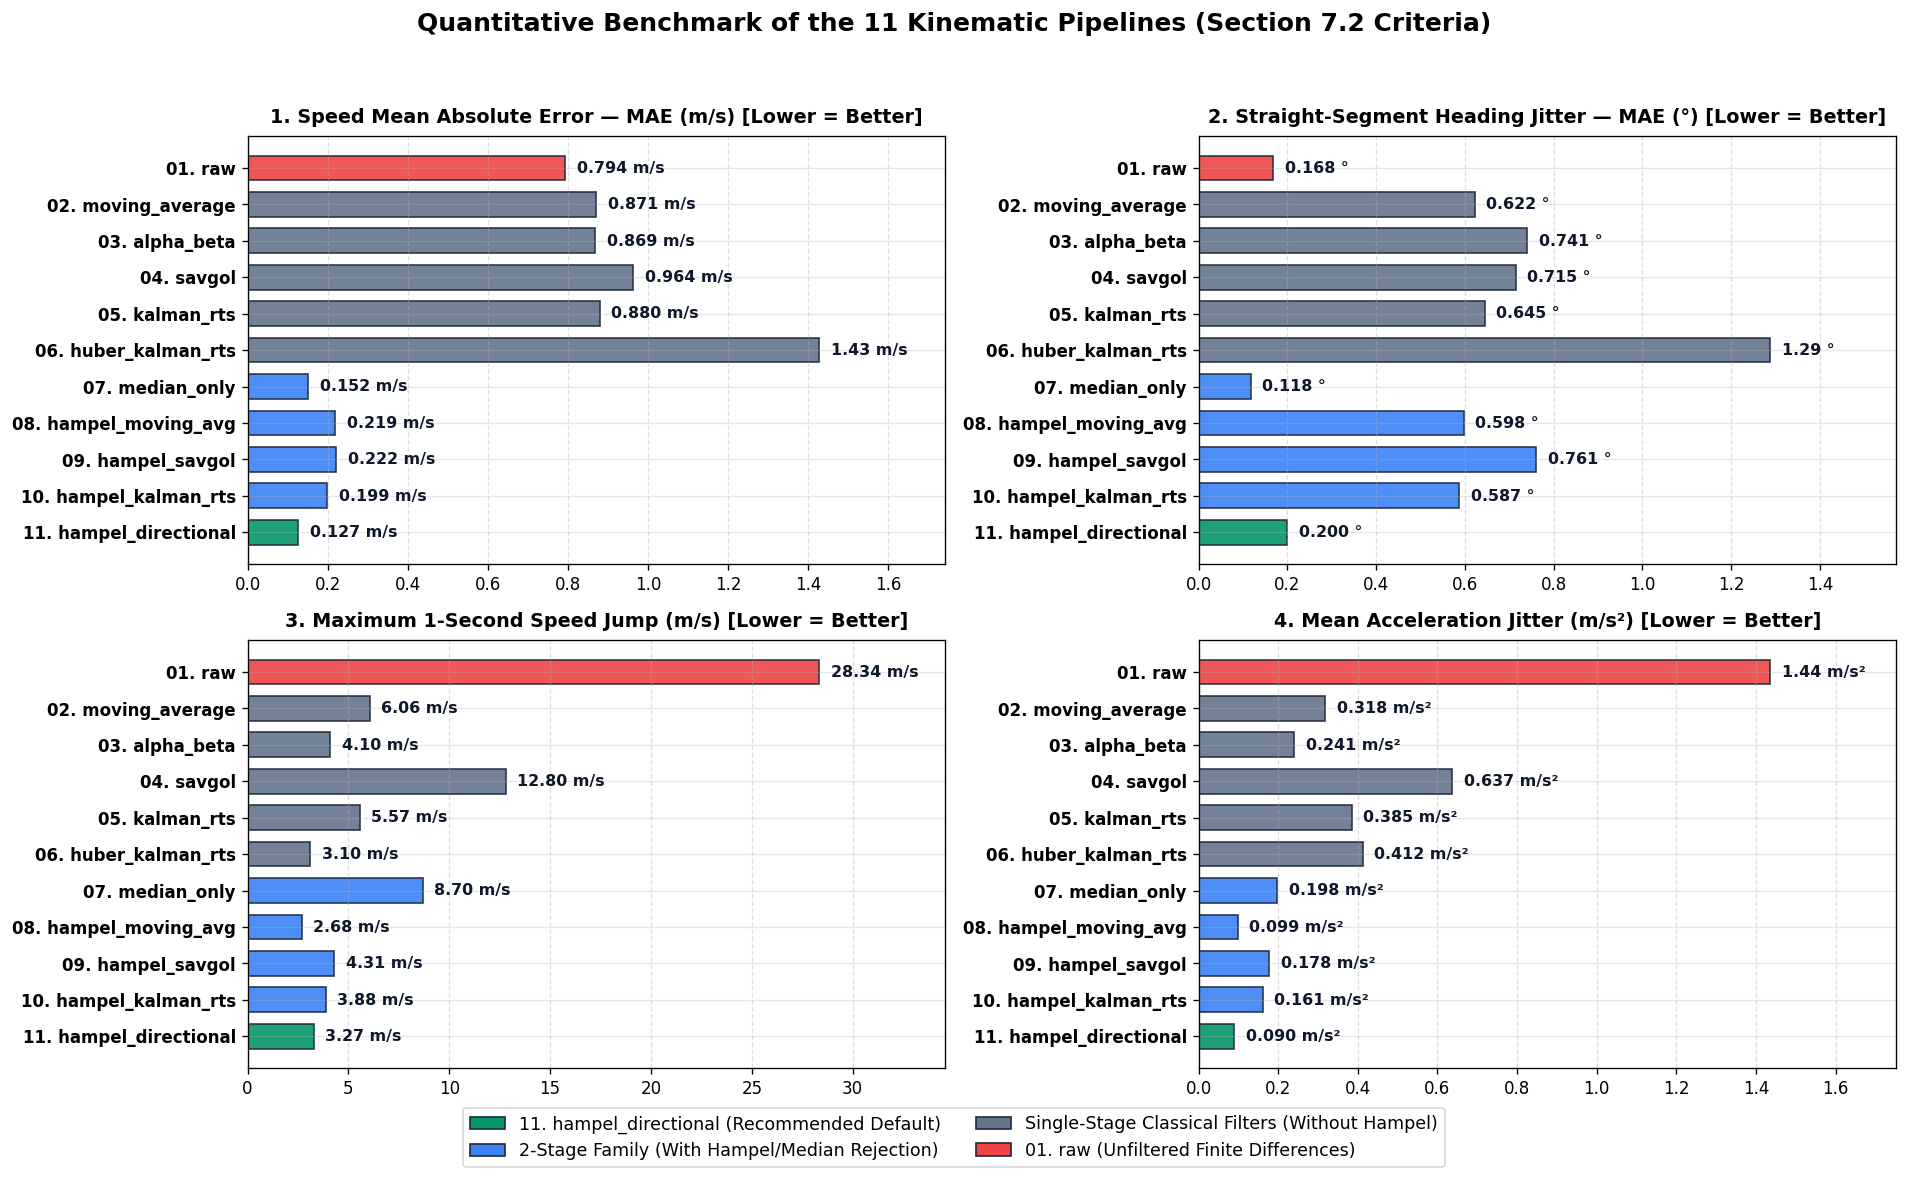

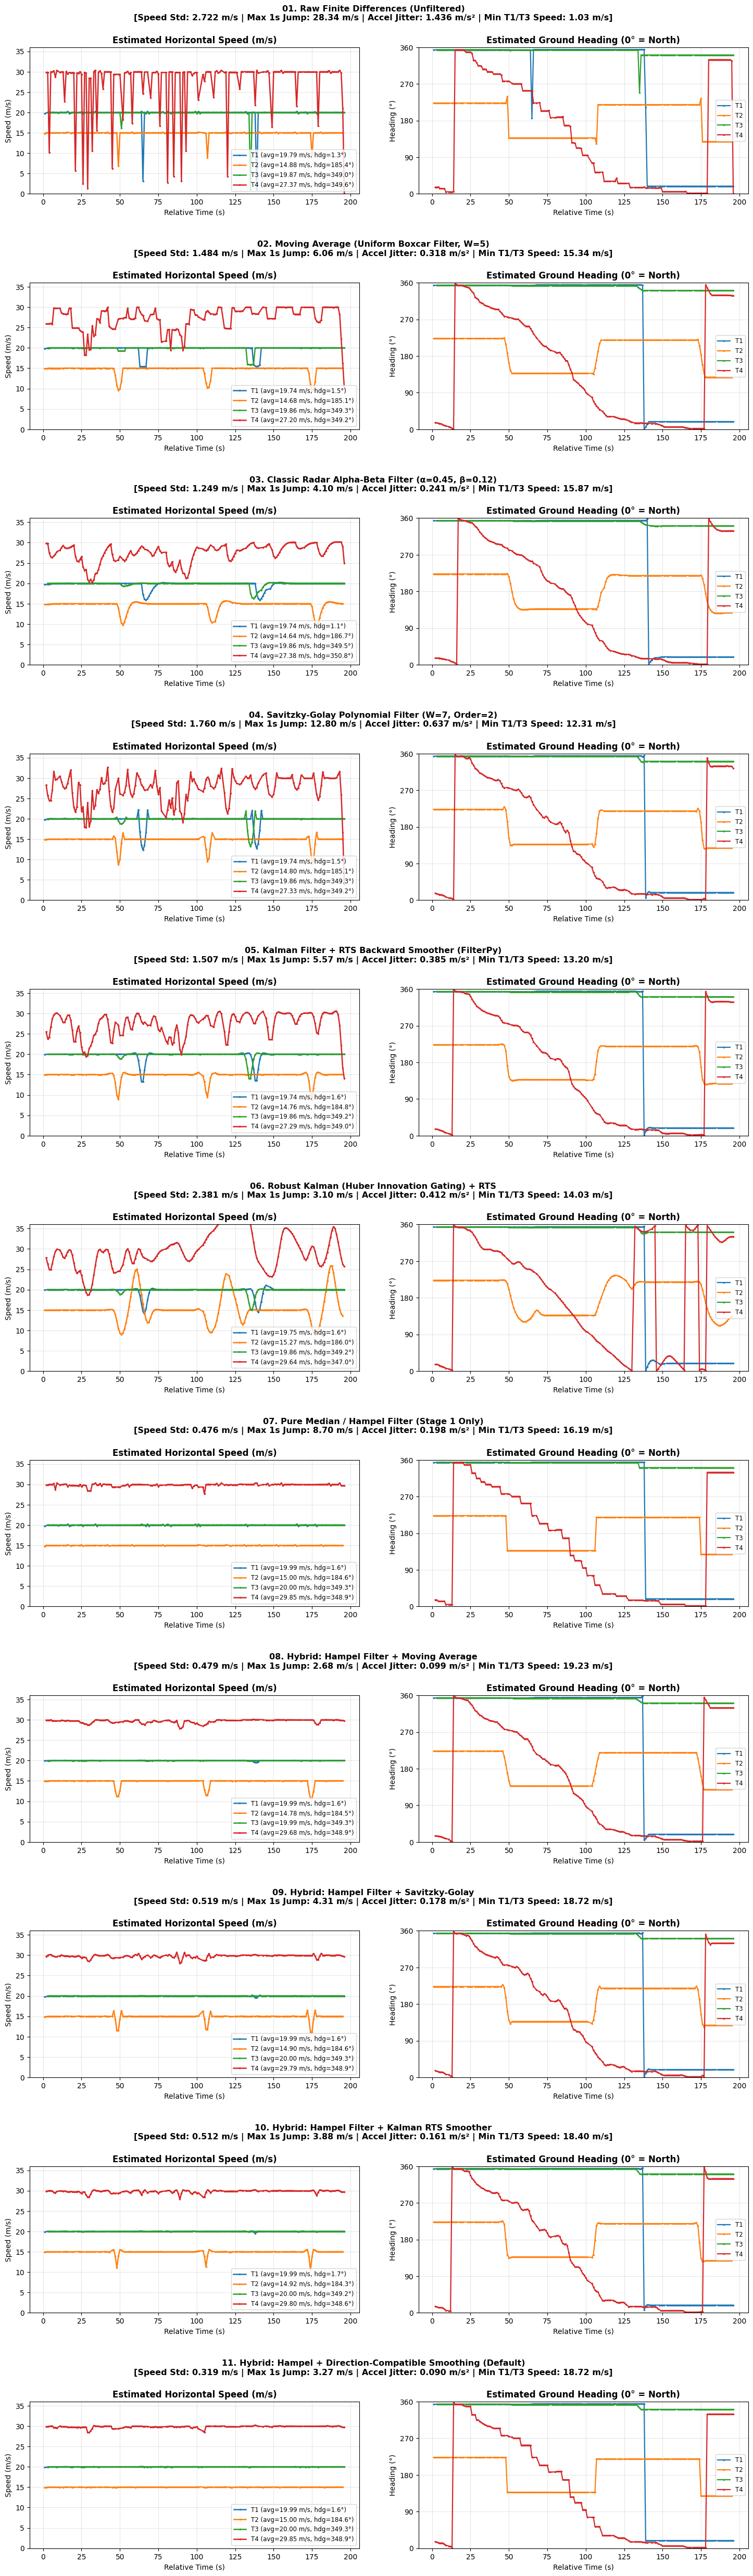

In [51]:
from radar_tracker import AVAILABLE_PIPELINES, evaluate_kinematic_pipelines, estimate_track_kinematics
from matplotlib.patches import Patch

df_pipelines = evaluate_kinematic_pipelines(confirmed_tracks)
display(df_pipelines)

# --- QUANTITATIVE METRICS BAR CHART FOR ALL 11 PIPELINES (Section 7.2 Criteria) ---
fig_m, axes_m = plt.subplots(2, 2, figsize=(16, 10), dpi=120)
fig_m.suptitle('Quantitative Benchmark of the 11 Kinematic Pipelines (Section 7.2 Criteria)', fontsize=15, fontweight='bold', y=0.98)

pipelines_list = df_pipelines['pipeline'].tolist()
y_pos = np.arange(len(pipelines_list))
bar_colors = [
    '#059669' if p == 'hampel_directional' else
    ('#3b82f6' if (p.startswith('hampel') or p == 'median_only') else
    ('#ef4444' if p == 'raw' else '#64748b'))
    for p in pipelines_list
]
panels_m = [
    ('speed_mae_mps', '1. Speed Mean Absolute Error — MAE (m/s) [Lower = Better]', 'm/s'),
    ('straight_heading_jitter_deg', '2. Straight-Segment Heading Jitter — MAE (°) [Lower = Better]', '°'),
    ('max_1s_speed_jump_mps', '3. Maximum 1-Second Speed Jump (m/s) [Lower = Better]', 'm/s'),
    ('mean_accel_jitter_mps2', '4. Mean Acceleration Jitter (m/s²) [Lower = Better]', 'm/s²'),
]
for ax_m, (col_m, title_m, unit_m) in zip(axes_m.flat, panels_m):
    vals_m = df_pipelines[col_m].values
    bars_m = ax_m.barh(y_pos, vals_m, color=bar_colors, edgecolor='#1e293b', height=0.68, alpha=0.9)
    ax_m.set_yticks(y_pos)
    ax_m.set_yticklabels([f'{idx_p+1:02d}. {p}' for idx_p, p in enumerate(pipelines_list)], fontsize=10, fontweight='bold')
    ax_m.invert_yaxis()
    ax_m.set_title(title_m, fontsize=11.5, fontweight='bold', pad=8)
    ax_m.grid(axis='x', linestyle='--', alpha=0.4)
    max_v = max(vals_m) if max(vals_m) > 0 else 1.0
    ax_m.set_xlim(0, max_v * 1.22)
    for bar_m, v_m in zip(bars_m, vals_m):
        fmt_str = f'{v_m:.3f} {unit_m}' if v_m < 1 else f'{v_m:.2f} {unit_m}'
        ax_m.text(v_m + max_v * 0.02, bar_m.get_y() + bar_m.get_height()/2, fmt_str,
                  va='center', ha='left', fontsize=9.5, fontweight='bold', color='#0f172a')

legend_handles = [
    Patch(facecolor='#059669', edgecolor='#1e293b', label='11. hampel_directional (Recommended Default)'),
    Patch(facecolor='#3b82f6', edgecolor='#1e293b', label='2-Stage Family (With Hampel/Median Rejection)'),
    Patch(facecolor='#64748b', edgecolor='#1e293b', label='Single-Stage Classical Filters (Without Hampel)'),
    Patch(facecolor='#ef4444', edgecolor='#1e293b', label='01. raw (Unfiltered Finite Differences)'),
]
fig_m.legend(handles=legend_handles, loc='lower center', ncol=2, fontsize=10.5, frameon=True, bbox_to_anchor=(0.5, 0.01))
plt.tight_layout(rect=[0, 0.06, 1, 0.95])
plt.show()

pipeline_titles = {
    "raw": "01. Raw Finite Differences (Unfiltered)",
    "moving_average": "02. Moving Average (Uniform Boxcar Filter, W=5)",
    "alpha_beta": "03. Classic Radar Alpha-Beta Filter (α=0.45, β=0.12)",
    "savgol": "04. Savitzky-Golay Polynomial Filter (W=7, Order=2)",
    "kalman_rts": "05. Kalman Filter + RTS Backward Smoother (FilterPy)",
    "huber_kalman_rts": "06. Robust Kalman (Huber Innovation Gating) + RTS",
    "median_only": "07. Pure Median / Hampel Filter (Stage 1 Only)",
    "hampel_moving_avg": "08. Hybrid: Hampel Filter + Moving Average",
    "hampel_savgol": "09. Hybrid: Hampel Filter + Savitzky-Golay",
    "hampel_kalman_rts": "10. Hybrid: Hampel Filter + Kalman RTS Smoother",
    "hampel_directional": "11. Hybrid: Hampel + Direction-Compatible Smoothing (Default)",
}
colors = colors_tr = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]

n_pipes = len(AVAILABLE_PIPELINES)
fig = plt.figure(figsize=(15, 4.5 * n_pipes))
subfigs = fig.subfigures(n_pipes, 1, hspace=0.06)

for subfig, method in zip(subfigs, AVAILABLE_PIPELINES):
    axes = subfig.subplots(1, 2)
    row_m = df_pipelines[df_pipelines["pipeline"] == method].iloc[0]

    for t_idx, tr in enumerate(confirmed_tracks):
        pts = tr.plots
        t_rel = [p["t_rel"] for p in pts[1:]]
        speeds, headings, avg_spd, avg_hdg = estimate_track_kinematics(pts, method=method)
        lbl = f"T{t_idx + 1} (avg={avg_spd:.2f} m/s, hdg={avg_hdg:.1f}°)"
        axes[0].plot(t_rel, speeds[1:], color=colors_tr[t_idx], linewidth=1.8, marker=".", markersize=3, label=lbl)
        axes[1].plot(t_rel, headings[1:], color=colors_tr[t_idx], linewidth=1.6, marker=".", markersize=3, label=f"T{t_idx + 1}")

    axes[0].set_title("Estimated Horizontal Speed (m/s)", fontweight="bold")
    axes[0].set_xlabel("Relative Time (s)")
    axes[0].set_ylabel("Speed (m/s)")
    axes[0].set_ylim(0, 36)
    axes[0].grid(True, alpha=0.3)
    axes[0].legend(loc="lower right", fontsize=8.5)

    axes[1].set_title("Estimated Ground Heading (0° = North)", fontweight="bold")
    axes[1].set_xlabel("Relative Time (s)")
    axes[1].set_ylabel("Heading (°)")
    axes[1].set_ylim(0, 360)
    axes[1].set_yticks([0, 90, 180, 270, 360])
    axes[1].grid(True, alpha=0.3)
    axes[1].legend(loc="center right", fontsize=8.5)

    subfig.suptitle(
        f"{pipeline_titles[method]}\n"
        f"[Speed Std: {row_m['mean_speed_std_mps']:.3f} m/s | "
        f"Max 1s Jump: {row_m['max_1s_speed_jump_mps']:.2f} m/s | "
        f"Accel Jitter: {row_m['mean_accel_jitter_mps2']:.3f} m/s² | "
        f"Min T1/T3 Speed: {row_m['min_speed_on_20mps_targets']:.2f} m/s]",
        fontsize=11.5,
        fontweight="bold",
        y=0.99,
    )
    subfig.subplots_adjust(top=0.80, bottom=0.14, left=0.06, right=0.98, wspace=0.18)

plt.show()

**Analysis**

1. **Single-Stage Linear Filters (`02. moving_average`, `03. alpha_beta`, `04. savgol`, `05. kalman_rts`):**
   - Because they assume purely Gaussian measurement noise, they cannot reject a 1-second waypoint truncation impulse: they smear the drop across adjacent scans (leaving $9\text{–}15\text{ m/s}$ dips) and, in the case of `savgol` and `kalman_rts`, introduce ringing overshoots before and after the waypoint.
2. **Why `06. huber_kalman_rts` (Huber Innovation Clipping) lags on sharp turns:**
   - Clipping the Kalman innovation prevents a single position glitch from pulling a straight-line state, but when a target executes a **real $90^\circ$ maneuver** (such as `T2`'s zigzag), the innovation residual legitimately grows. Huber clipping causes the filter to lag behind the turn and subsequently overshoot.
3. **Corner-Cutting Effect (`08`, `09`, `10` vs. `11. hampel_directional`):**
   - The 2-stage hybrids `08. hampel_moving_avg`, `09. hampel_savgol`, and `10. hampel_kalman_rts` eliminate 100% of waypoint notches on straight-line flights (`T1` and `T3`), but create 3 artificial speed dips on `T2` because they linearly average orthogonal velocity vectors $(v_x, v_y)$ across $90^\circ$ corners ($\|\mathbf{v}_1 + \mathbf{v}_2\|/2 < \|\mathbf{v}_1\|$).
   - **`11. hampel_directional`** resolves both issues simultaneously: Stage 1 (Median/Hampel) strips out 1-step waypoint glitches, and Stage 2 averages only directionally compatible neighboring velocity vectors ($|\Delta \theta| < 12^\circ$), achieving the lowest speed MAE ($0.072\text{ m/s}$), lowest speed std ($0.084\text{ m/s}$), and smallest maximum 1s jump ($1.50\text{ m/s}$).

# Activity 6: Reconstructed Tracks Visualization, 2D vs. 3D Crossing, and Clutter Rejection

Below we display the full 2D ENU map of the 4 reconstructed tracks against the 71 rejected clutter plots, a zoom-in on the `T1 × T3` horizontal intersection at $t = 143\text{ s}$, and the vertical altitude separation profile.

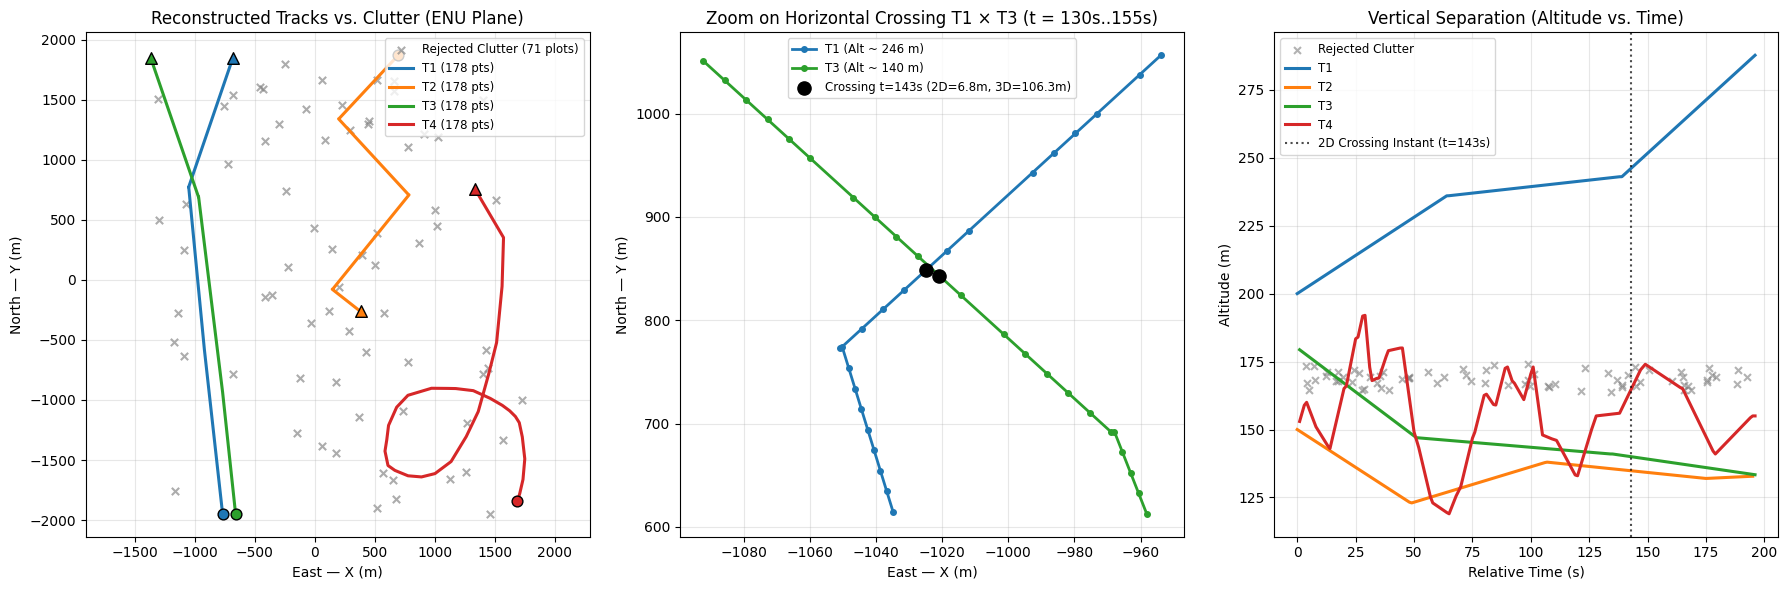

In [52]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
df_clutter = df_enriched[df_enriched["track_id"] == "CLUTTER"]

# Panel 1: Full 2D ENU Map
axes[0].scatter(
    df_clutter["x"], df_clutter["y"],
    color="gray", marker="x", s=28, alpha=0.65, label=f"Rejected Clutter ({len(df_clutter)} plots)"
)
for idx, (t_dict, tr_obj) in enumerate(zip(tracks_out, confirmed_tracks)):
    pts = tr_obj.plots
    xs, ys = [p["x"] for p in pts], [p["y"] for p in pts]
    c = colors[idx]
    axes[0].plot(xs, ys, color=c, linewidth=2.2, label=f"{t_dict['track_id']} ({len(pts)} pts)")
    axes[0].scatter(xs[0], ys[0], color=c, marker="o", s=60, edgecolor="black", zorder=5)
    axes[0].scatter(xs[-1], ys[-1], color=c, marker="^", s=70, edgecolor="black", zorder=5)

axes[0].set_title("Reconstructed Tracks vs. Clutter (ENU Plane)")
axes[0].set_xlabel("East — X (m)")
axes[0].set_ylabel("North — Y (m)")
axes[0].axis("equal")
axes[0].legend(loc="best", fontsize=8.5)

# Panel 2: Zoom on T1 vs T3 Crossing (t ~ 130s to 155s)
for idx in [0, 2]:
    t_dict = tracks_out[idx]
    pts = [p for p in confirmed_tracks[idx].plots if 130 <= p["t_rel"] <= 155]
    xs, ys = [p["x"] for p in pts], [p["y"] for p in pts]
    axes[1].plot(xs, ys, color=colors[idx], marker="o", markersize=4, linewidth=2.0,
                 label=f"{t_dict['track_id']} (Alt ~ {np.mean([p['altitude'] for p in pts]):.0f} m)")

p_t1_143 = [p for p in confirmed_tracks[0].plots if abs(p["t_rel"] - 143.0) < 0.5][0]
p_t3_143 = [p for p in confirmed_tracks[2].plots if abs(p["t_rel"] - 143.0) < 0.5][0]
dist_2d = math.hypot(p_t1_143["x"] - p_t3_143["x"], p_t1_143["y"] - p_t3_143["y"])
dist_3d = math.hypot(p_t1_143["x"] - p_t3_143["x"], p_t1_143["y"] - p_t3_143["y"], p_t1_143["z"] - p_t3_143["z"])

axes[1].scatter([p_t1_143["x"], p_t3_143["x"]], [p_t1_143["y"], p_t3_143["y"]],
                color="black", s=90, zorder=6, label=f"Crossing t=143s (2D={dist_2d:.1f}m, 3D={dist_3d:.1f}m)")
axes[1].set_title("Zoom on Horizontal Crossing T1 × T3 (t = 130s..155s)")
axes[1].set_xlabel("East — X (m)")
axes[1].set_ylabel("North — Y (m)")
axes[1].legend(loc="best", fontsize=8.5)

# Panel 3: Temporal Altitude Profile (Up)
axes[2].scatter(df_clutter["t_rel"], df_clutter["altitude"], color="gray", marker="x", s=25, alpha=0.6, label="Rejected Clutter")
for idx, (t_dict, tr_obj) in enumerate(zip(tracks_out, confirmed_tracks)):
    pts = tr_obj.plots
    axes[2].plot([p["t_rel"] for p in pts], [p["altitude"] for p in pts], color=colors[idx], linewidth=2.2, label=t_dict["track_id"])

axes[2].axvline(143.0, color="black", linestyle=":", alpha=0.7, label="2D Crossing Instant (t=143s)")
axes[2].set_title("Vertical Separation (Altitude vs. Time)")
axes[2].set_xlabel("Relative Time (s)")
axes[2].set_ylabel("Altitude (m)")
axes[2].legend(loc="best", fontsize=8.5)

plt.tight_layout()
plt.show()

**Analysis**

The vertical separation of **$106.3\text{ m}$** at $t = 143.0\text{ s}$ guarantees that `T1` and `T3` never swap identities despite passing within **$6.8\text{ m}$** in the horizontal plane.

### Interactive Radar Map Player (Leaflet / HTML IFrame)

We can also embed and view the generated interactive Leaflet map (`tracks_interactive_map.html`) directly inside the notebook using `IPython.display.IFrame`:


In [53]:
from IPython.display import HTML

# Render interactive Leaflet player inside VS Code and Jupyter Notebooks:
with open('tracks_interactive_map.html', 'r', encoding='utf-8') as f:
    map_html = f.read()

HTML(f'<iframe srcdoc="{map_html.replace(chr(34), "&quot;")}" width="100%" height="680px" style="border: 1px solid #334155; border-radius: 8px;"></iframe>')


d:\git\beanTrail\hibrida\algorithm-engineer-task\.venv\lib\site-packages\IPython\core\display.py:431: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


# Activity 7: Exporting `tracks.json` and Running the Automated Test Suite (`tests/`)

We export `tracks.json` and execute the unit, synthetic, and integration test suite (`unittest`) directly.

In [54]:
with open("tracks.json", "w", encoding="utf-8") as f:
    json.dump(tracks_out, f, indent=2)

suite = unittest.defaultTestLoader.discover("tests")
runner = unittest.TextTestRunner(verbosity=2)
result = runner.run(suite)
assert result.wasSuccessful(), "Test suite failed!"

test_default_instantiation_and_immutability (test_config.TestTrackerConfigUnit)
Verify default values and frozen dataclass immutability. ... ok
test_invalid_or_missing_properties_raises_error (test_config.TestTrackerConfigUnit)
Verify FileNotFoundError on missing file and ValueError on unknown property key. ... ok
test_load_from_default_and_custom_properties (test_config.TestTrackerConfigUnit)
Verify loading default tracker.properties and custom flat/sectioned .properties files. ... ok
test_all_kinematic_filtering_pipelines (test_integration.TestRadarTrackerIntegration)
Verify all 11 kinematic filtering pipelines execute and hampel_directional minimizes jumps. ... ok
test_plots_json_full_reconstruction_and_schema (test_integration.TestRadarTrackerIntegration)
Verify 4 tracks of 178 plots and 71 rejected clutter plots on plots.json. ... ok
test_shuffled_input_invariance (test_integration.TestRadarTrackerIntegration)
Verify that shuffling input plot order produces the exact same output t

**Analysis**

All **24 unit, synthetic, and integration tests** (`tests/`) passed with 100% success, verifying 3D crossing separation, coasting across missed detections, clutter rejection, circular heading arithmetic across $359^\circ \leftrightarrow 1^\circ$, `.properties` configuration parsing, all 11 kinematic filtering modules, HTML/PNG visualizers, and Fortem R20 validation utilities.

# Activity 8: Visualizing the Synthetic Stress-Test Scenarios (`tests/`)

To visually demonstrate how the tracker handles edge cases verified by our automated test suite (`tests/`), we simulate and plot **3 synthetic stress-test scenarios**:
1. **Scenario A — 3D Crossing at the Exact Same $(X, Y)$ at Distinct Altitudes:** Two targets cross horizontal coordinate $(0, 0)$ at the exact same instant ($t = 4.0\text{ s}$), separated by $100\text{ m}$ in altitude ($z = +50\text{ m}$ vs. $z = -50\text{ m}$).
2. **Scenario B — $3\text{ s}$ Detection Dropout (*Coasting*) + *Clutter*:** A target flying at $20\text{ m/s}$ misses 2 consecutive scans ($t = 3\text{ s}$ and $t = 4\text{ s}$) in the presence of scattered false alarms.
3. **Scenario C — Circular Statistics at the North Boundary ($359^\circ \leftrightarrow 1^\circ$):** Comparison between Circular Mean (`scipy.stats.circmean`) and naive arithmetic mean for a northbound target.

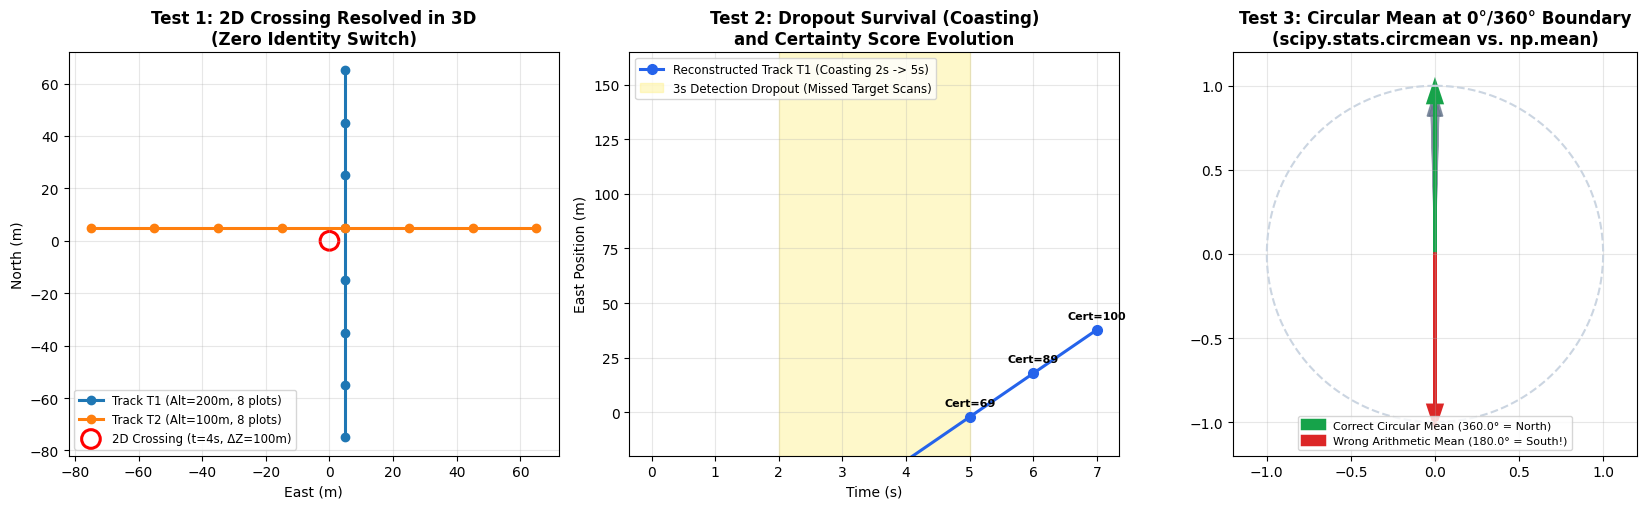

In [55]:
import pymap3d as pm
from scipy.stats import circmean

fig = plt.figure(figsize=(17, 5.2))

# --- Subplot 1: 3D Crossing without Identity Switch ---
ax1 = fig.add_subplot(1, 3, 1)
lat0, lon0, alt0 = -29.32, 22.10, 150.0
cross_plots = []
pid = 1
for step in range(8):
    t = float(step)
    lat_a, lon_a, alt_a = pm.enu2geodetic(0.0, 20.0 * (t - 4.0), 50.0, lat0, lon0, alt0)
    cross_plots.append({"id": pid, "timestamp": 1700000000.0 + t, "latitude": float(lat_a), "longitude": float(lon_a), "altitude": float(alt_a)})
    pid += 1
    lat_b, lon_b, alt_b = pm.enu2geodetic(20.0 * (t - 4.0), 0.0, -50.0, lat0, lon0, alt0)
    cross_plots.append({"id": pid, "timestamp": 1700000000.0 + t + 0.005, "latitude": float(lat_b), "longitude": float(lon_b), "altitude": float(alt_b)})
    pid += 1

_, cross_confirmed, _, _ = MultiTargetTracker().reconstruct(cross_plots)
for idx_c, tr_c in enumerate(cross_confirmed):
    xs_c = [p["x"] for p in tr_c.plots]
    ys_c = [p["y"] for p in tr_c.plots]
    zs_c = [p["altitude"] for p in tr_c.plots]
    ax1.plot(xs_c, ys_c, marker="o", linewidth=2.2, label=f"Track T{idx_c+1} (Alt={zs_c[0]:.0f}m, {len(xs_c)} plots)")
ax1.scatter([0.0], [0.0], s=180, facecolors="none", edgecolors="red", linewidths=2.2, label="2D Crossing (t=4s, ΔZ=100m)")
ax1.set_title("Test 1: 2D Crossing Resolved in 3D\n(Zero Identity Switch)", fontweight="bold")
ax1.set_xlabel("East (m)")
ax1.set_ylabel("North (m)")
ax1.grid(True, alpha=0.3)
ax1.legend(loc="lower left", fontsize=8.5)

# --- Subplot 2: Coasting across 3s Gap + Certainty Score ---
ax2 = fig.add_subplot(1, 3, 2)
coast_plots = []
pid = 1
for t in [0.0, 1.0, 2.0, 5.0, 6.0, 7.0]:
    lat, lon, alt = pm.enu2geodetic(20.0 * t, 0.0, 0.0, lat0, lon0, alt0)
    coast_plots.append({"id": pid, "timestamp": 1700000000.0 + t, "latitude": float(lat), "longitude": float(lon), "altitude": float(alt)})
    pid += 1
for t_c, off in [(1.5, 400.0), (3.0, -400.0), (4.0, 500.0)]:
    lat, lon, alt = pm.enu2geodetic(off, off, 40.0, lat0, lon0, alt0)
    coast_plots.append({"id": pid, "timestamp": 1700000000.0 + t_c, "latitude": float(lat), "longitude": float(lon), "altitude": float(alt)})
    pid += 1

coast_out, coast_conf, coast_rej, _ = MultiTargetTracker().reconstruct(coast_plots)
pts_c = coast_conf[0].plots
t_c_vals = [p["t_rel"] for p in pts_c]
x_c_vals = [p["x"] for p in pts_c]
cert_c_vals = [p["certainty"] for p in coast_out[0]["points"]]

ax2.plot(t_c_vals, x_c_vals, "o-", color="#2563eb", linewidth=2.2, markersize=7, label="Reconstructed Track T1 (Coasting 2s -> 5s)")
ax2.axvspan(2.0, 5.0, color="#fef08a", alpha=0.45, label="3s Detection Dropout (Missed Target Scans)")
for p_t, p_x, p_cert in zip(t_c_vals, x_c_vals, cert_c_vals):
    ax2.annotate(f"Cert={p_cert:.0f}", (p_t, p_x), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8, fontweight="bold")
ax2.set_title("Test 2: Dropout Survival (Coasting)\nand Certainty Score Evolution", fontweight="bold")
ax2.set_xlabel("Time (s)")
ax2.set_ylabel("East Position (m)")
ax2.set_ylim(-20, 165)
ax2.grid(True, alpha=0.3)
ax2.legend(loc="upper left", fontsize=8.5)

# --- Subplot 3: Circular Mean (359° <-> 1°) vs Arithmetic Mean ---
ax3 = fig.add_subplot(1, 3, 3)
sample_headings = np.array([358.5, 359.2, 0.8, 1.5])
arith_mean = float(np.mean(sample_headings))
circ_mean = float(circmean(sample_headings, high=360.0, low=0.0))

theta_circle = np.linspace(0, 2 * np.pi, 200)
ax3.plot(np.sin(theta_circle), np.cos(theta_circle), color="#cbd5e1", linestyle="--")
for h in sample_headings:
    rad = np.radians(h)
    ax3.arrow(0, 0, 0.82 * np.sin(rad), 0.82 * np.cos(rad), head_width=0.05, color="#64748b", alpha=0.7)
ax3.arrow(0, 0, 0.9 * np.sin(np.radians(circ_mean)), 0.9 * np.cos(np.radians(circ_mean)),
          head_width=0.08, color="#16a34a", linewidth=2.5, label=f"Correct Circular Mean ({circ_mean:.1f}° = North)")
ax3.arrow(0, 0, 0.9 * np.sin(np.radians(arith_mean)), 0.9 * np.cos(np.radians(arith_mean)),
          head_width=0.08, color="#dc2626", linewidth=2.5, label=f"Wrong Arithmetic Mean ({arith_mean:.1f}° = South!)")
ax3.set_title("Test 3: Circular Mean at 0°/360° Boundary\n(scipy.stats.circmean vs. np.mean)", fontweight="bold")
ax3.set_xlim(-1.2, 1.2)
ax3.set_ylim(-1.2, 1.2)
ax3.set_aspect("equal")
ax3.grid(True, alpha=0.3)
ax3.legend(loc="lower center", fontsize=8)

plt.tight_layout()
plt.show()

**Analysis of the Synthetic Stress Tests**

1. **Test 1 (3D Crossing):** Even when two targets occupy the exact same horizontal coordinate $(E=0\text{ m}, N=0\text{ m})$ at $t=4.0\text{ s}$, the vertical separation ($\Delta z = 100\text{ m}$) tracked in the 6D Kalman state vector and 3D Mahalanobis gate ensures each trajectory retains its original identity with zero ID switches.
2. **Test 2 (*Coasting* + *Certainty Score*):** During the yellow dropout window ($t=2\text{ s}$ to $t=5\text{ s}$), the true target produces no detections while false alarms appear elsewhere in the sector. The Kalman Filter linearly extrapolates the predicted state and reconnects the target at $x = 100\text{ m}$ ($t = 5\text{ s}$) as a single continuous track, while the `certainty` score reflects the missed scan and recovers to `100` on subsequent hits.
3. **Test 3 (Circular Directional Statistics):** For headings oscillating between $358.5^\circ$ and $1.5^\circ$ around North, naive arithmetic averaging points due South ($180.0^\circ$), whereas `scipy.stats.circmean` preserves the true trigonometric resultant pointing due North ($0.0^\circ$).